In [5]:
from pathlib import Path
import sys

path = Path().resolve().parents[1]

if str(path) not in sys.path:
    sys.path.append(str(path))

# Multi-Head Attention

Aplicando multiplos Attention em paralelo e concatenar os resultados.

## 1. Por que Multi-Head Attention?

- Problema de frases ambíguas

Para iniciarmos o estudo do Multi-Head Attention (MHA) vamos analisar a seguinte frase: "O policial abateu o ladrão com uma faca".

A primeira pergunta que devemos fazer é, quem estava com a faca? O polícial ou o ladrão? Partindo desse ponto vamos relembrar o que vimos no notebook passado: **Self-Attention**. 

Caso calculemos a atenção da palavra faca, podemos ter a seguinte distribuição probabilistica:


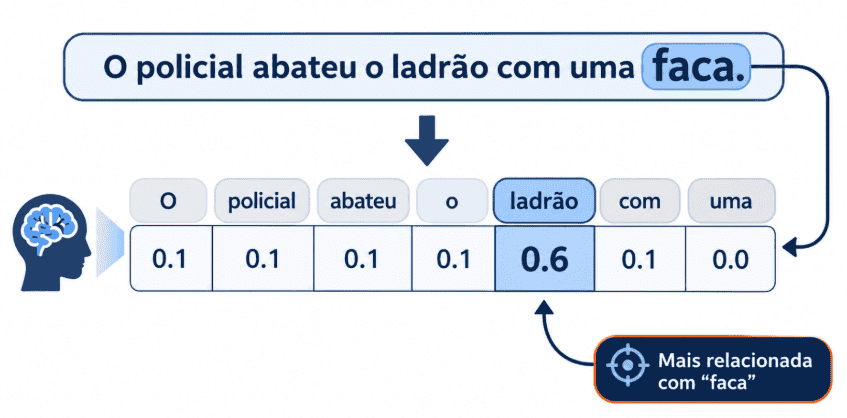

Partindo dessa analise verificamos que a palavra **ladrão** é a mais relacionada ao token "faca" nesse contexto. O único problema dessa abordagem é que assumimos apenas essa perspectiva, sem considerar outras nuances como, justamente, a possibilidade da palavra faca estar se referindo ao ladrão. Seria extremamente interessante conseguir inserir outras perspectivas para essa analise, sem aumentar muito o custo computacional e diferentes padrões de interação simultaneamente. Certo?

Justamente por esse motivo surge o **Multi-Head Attention.**


## 2. O que é MHA?


- Separando os heads (dividindo as dimensões):


Imagine que tenhamos uma representação dos dados de entrada em uma matriz de ( 3 x 512 ), ou seja, 3 tokens representados por vetores de 512 dimensões. Caso seja aplicado o Self-Attention sobre esse conjunto de dados *(chamado **single head**)*, ele deve gerar um output contextualizado apenas considerando essa perspectiva (calculado pelo mesmo conjunto de pesos). Então o que podemos fazer para inserir outros pontos de vista?

Projetar múltiplos heads! Onde cada head possui suas próprias projeções aprendíveis de Query, Key e Value. Elas recebem a mesma sequência de entrada, mas transformam suas representações em espaços diferentes. Para isso vamos dividir o número de dimensões da representação de entrada original pelo numero de heads que queremos projetar o modelo ( basicamente pelo número de perspectivas distintas que queremos analisar os dados ):

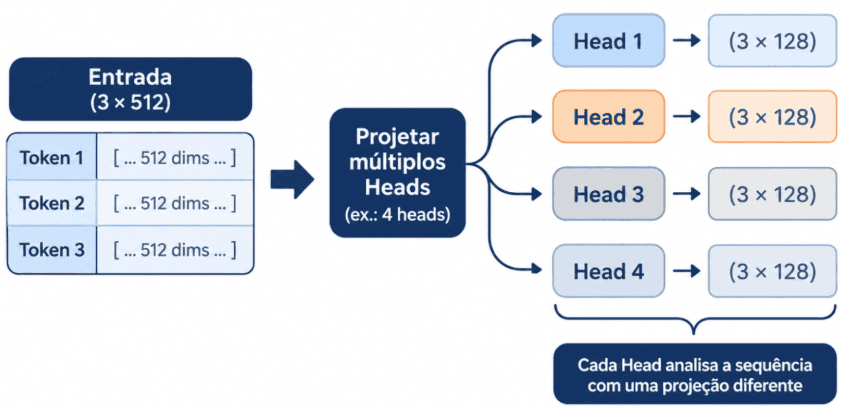

-  Vantagem Computacional ( 4 heads aprendendo padrões distindos ):

Agora, além de termos 4 pontos de vistas distintos sobre os dados ( como se fossem 4 investigadores diferentes analisando o mesmo caso ), conseguimos executar múltiplas heads em paralelo com um custo computacional de ordem semelhante ao de uma única head que utiliza a dimensão completa. Por que?

Pois apesar de aumentarmos o número de conjuntos processados em paralelo, reduzimos proporcionalmente o número de dimensões de cada representação ( ler observação ao fim da explicação * ).


- Ilustrando multiplas perspectivas:

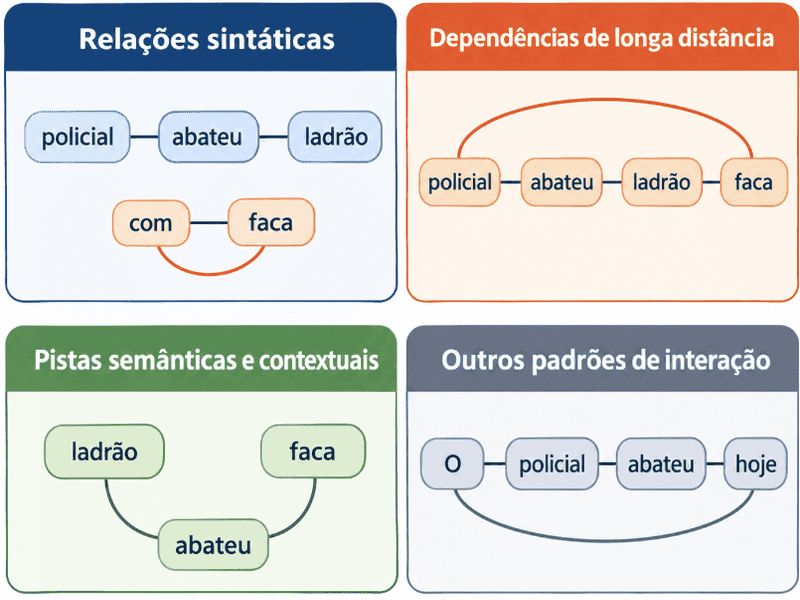

Podemos entender a detecção de padrões distintas em cada head como a imagem ilustrada acima: um head procura relações sintáticas, outro relações entre palavras distantes, enquanto outro procura outras características contextuais e etc.
Não é exatamente assim que isso acontece pois não temos como saber explícitamente quais padrões estão sendo priorizados em cada head, mas a ideia é termos em mente justamente isso: cada head aprende padrões distintos.

## 3. Como funciona?

#### 1. Projeções independentes para cada head:

Inicialmente, recebemos a matriz de entrada X e aplicamos diferentes projeções lineares para obter os conjuntos de Queries, Keys e Values de cada head:

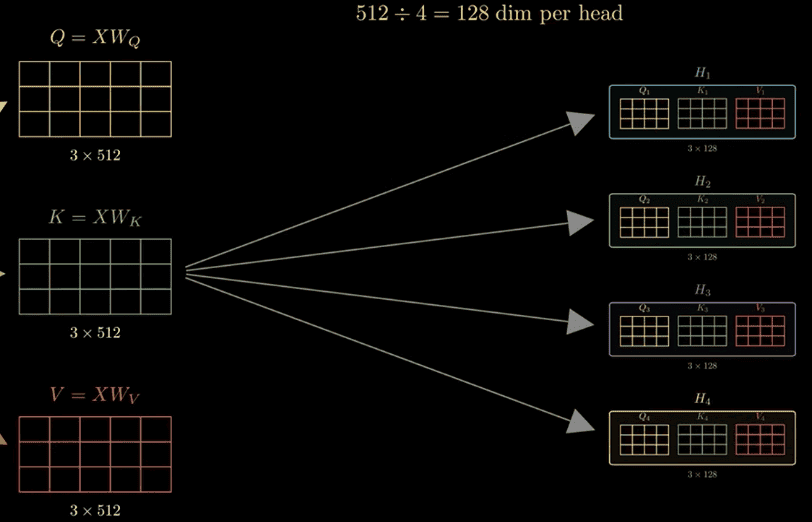

Ao obtermos os heads separados podemos seguir para o proximo passo: executar o mecanismo de Scaled Dot-Product Attention em cada um desses heads, cada um com seus respectivos Queries, Keys e Values. 

Com isso vamos obter diferentes matrizes de saída, com padrões dinstintos e com o número de dimensões proporcionalmente menor.


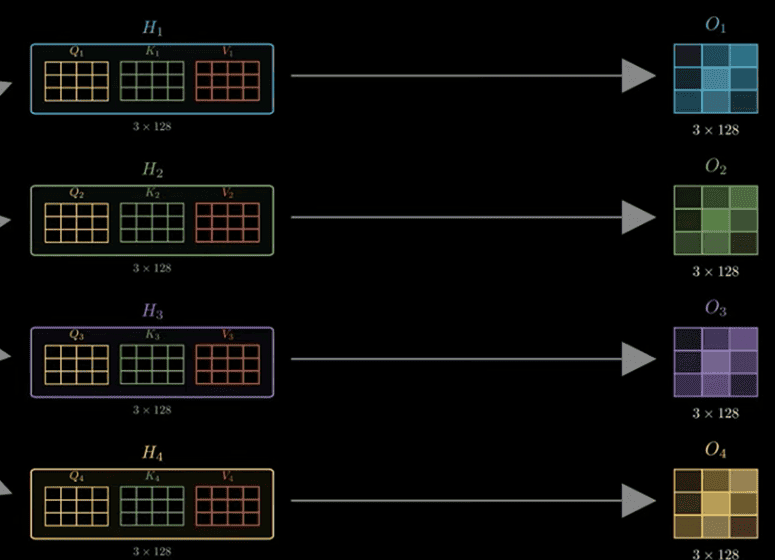

#### 2. Concatenar outputs

Logo em seguida, precisamos agrupar os resultados das diferentes heads.

Como cada um deles foi separado proporcionalmente ao número de heads, podemos simplesmente concatena-los e o número de dimensões vai voltar a ser o número de dimensões originais, fazendo com que recuperemos o formato dos dados iniciais.

$$
[3\times128]\rightarrow[3\times512]
$$


#### 3. Projetando Output:

Entretanto apenas concatenas os resultados não significa combinar e transformera as informações aprendidas pelos diferentes heads.

Para isso aplicamos uma última camada Linear utilizando a matriz de pesos aprendiveis o_weights.

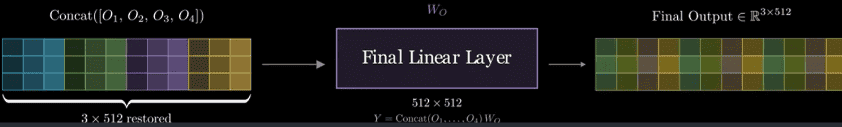

Por meio dessa projeção é possível combinar as características produzidas pelos diferentes heads e gerar a representação final do Multi-Head Attention.

obs* : É importante entender que cada head não recebe exatamente as caracteristicas das originais em sua representação final, mas sim cada head recebe projeções para um espaço calculado por (num_dim/num_heads). Ou seja, prende projeções para um espaço de dimensão menor.

A exemplo disso, caso os tokens originais fossem representados por 512 dimensões, cada nova projeção deles (caso queiramos dividir em 4 heads) terá 128 dimensões.

Isso não significa que cada Head analisa apenas uma parte dos tokens, o que muda é a dimensão das características utilizadas para calcular a atenção.

In [6]:
import torch.nn as nn
import torch
from src.model import scaled_dot_product_attention

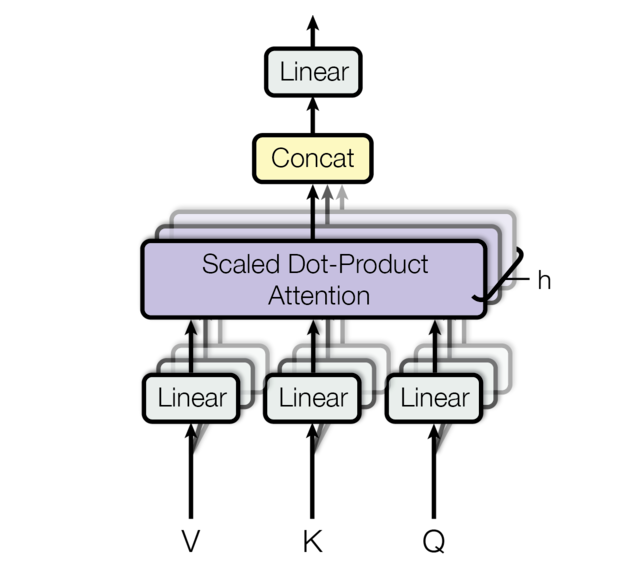

In [7]:
class MultiHeadAttention(nn.Module):
    def __init__(
        self,
        d_model: int,
        num_heads:int,
        device: torch.device,
        dropout=0.1
    ):
        #definindo o numero de dimensões de cada head
        super().__init__()

        if d_model % num_heads != 0:
            raise ValueError("d_model deve ser divisível por num_heads")

        self.d_model = d_model
        self.head_dim = d_model // num_heads
        self.num_heads = num_heads
        self.dropout = nn.Dropout(dropout)

        #fazendo as camadas lineares
        self.q_proj = nn.Linear(
            d_model,
            d_model,
            device=device
        )

        self.k_proj = nn.Linear(
            d_model,
            d_model,
            device=device
        )

        self.v_proj = nn.Linear(
            d_model,
            d_model,
            device=device
        )
 
        self.o_proj = nn.Linear(
            d_model,
            d_model,
            device=device
        )


    def _split_heads(self, x): # [B, L, d]
        batch_size, seq_len, _ = x.shape

        x = x.view(
            batch_size,
            seq_len,
            self.num_heads,
            self.head_dim
        ) # [B, L, h, d]

        return x.transpose(1,2) # [B, h, L, d]

    def _merge_heads(self, x): # [B, h, L, d]
        batch_size, _  , seq_len,  _ = x.shape

        x = x.transpose(1,2).contiguous() #[B, L, h, d]

        x = x.view(
            batch_size,
            seq_len,
            self.num_heads * self.head_dim 
        )

        return x # [B, L, h * d]

    
    def forward(
        self,
        query: torch.Tensor,
        key: torch.Tensor,
        value: torch.Tensor,
        attn_mask: torch.Tensor | None = None
    ):

        #criando as camadas lineares e separando heads
        query = self._split_heads(self.q_proj(query))
        key = self._split_heads(self.k_proj(key))
        value = self._split_heads(self.v_proj(value))

        #aplicando o attention
        attn_output = scaled_dot_product_attention(
            q=query,
            k=key,
            v=value,
            attn_mask=attn_mask
        )

        #concatenando heads
        x = self._merge_heads(attn_output) #[B, L, h * d]

        #projetando a camada de output
        x = self.o_proj(x)

        return self.dropout(x) # [B, L, d_model]